# College Admissions and Tuition Analysis

## Project Overview

This project analyzes data from 777 U.S. colleges and universities. It combines data cleaning, exploratory data analysis, feature engineering, visualization, correlation analysis, and hypothesis testing to investigate institutional selectivity, tuition, enrollment, and faculty credentials.

## Research Questions

1. Are private universities generally more expensive than public universities?
2. Are larger universities more expensive than smaller universities?
3. Is university size strongly related to out-of-state tuition?
4. Is acceptance rate related to the percentage of students from the top 10% of their high-school class?
5. Are universities with a higher percentage of PhD-qualified faculty more selective?
6. Does higher tuition reduce the number of applications?

## Skills Demonstrated

- Data loading and validation with pandas
- Data cleaning and column standardization
- Exploratory data analysis
- Feature engineering
- Matplotlib and Seaborn visualization
- Correlation analysis
- Pearson hypothesis testing
- Interpretation of statistical results

## Dataset and provenance

| | |
|---|---|
| **What** | 777 US colleges and universities, 18 variables: admissions (applications, acceptances, enrollment), incoming-student quality (top 10% / 25% of high-school class), tuition and costs, faculty credentials, student/faculty ratio, alumni giving, expenditure, graduation rate |
| **Period** | A single cross-section: the **1995** issue of US News & World Report. Dollar amounts are 1995 dollars, and the results describe 1995, not today |
| **Source** | The `College` data in the ISLR R package v1.4 (James, Witten, Hastie & Tibshirani, *An Introduction to Statistical Learning*), originally from the StatLib library at Carnegie Mellon (ASA Statistical Graphics Section, 1995 Data Analysis Exposition) |
| **License** | Distributed with ISLR under GPL-2. Not redistributed here: `python get_college_data.py` downloads it to `data/College.csv` |


> **Required file:** `data/College.csv`. From the repository root, run `python get_college_data.py` once, then run this notebook top to bottom (Kernel → Restart & Run All).

## 1. Import Libraries


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 2. Load the Dataset


In [2]:
def load_college_data() -> pd.DataFrame:
    """Load data/College.csv, whether the notebook runs from notebooks/ or the repo root."""
    for path in (Path("data/College.csv"), Path("../data/College.csv")):
        if path.exists():
            print(f"Loading dataset from: {path}")
            return pd.read_csv(path)
    raise FileNotFoundError(
        "data/College.csv not found. From the repository root, run:  python get_college_data.py"
    )


college = load_college_data()
print(f"Loaded {college.shape[0]} rows and {college.shape[1]} columns.")
assert college.shape == (777, 19), "Expected 777 colleges and 19 columns (18 variables + Names)"
college.head()

Loading dataset from: ../data/College.csv
Loaded 777 rows and 19 columns.


,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate,Names
0,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60,Abilene Christian University
1,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56,Adelphi University
2,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54,Adrian College
3,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59,Agnes Scott College
4,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15,Alaska Pacific University


## 3. Data Cleaning and Preparation


In [3]:
# Use college names as the index when the Names column is available.
if "Names" in college.columns:
    college = college.set_index("Names", drop=False)

# Standardize column names for easier analysis.
college = college.rename(
    columns={
        "Grad.Rate": "grad_rate",
        "S.F.Ratio": "student_faculty_ratio",
        "perc.alumni": "alumni_donation_rate",
        "Room.Board": "room_board",
        "F.Undergrad": "full_time_undergrad",
        "P.Undergrad": "part_time_undergrad",
    }
)

college.columns = (
    college.columns
    .str.strip()
    .str.lower()
    .str.replace(".", "_", regex=False)
)

# Fill missing application values with zero, following the original project specification.
if "apps" in college.columns:
    college["apps"] = college["apps"].fillna(0)

print("Duplicate rows:", college.duplicated().sum())
college.info()


Duplicate rows: 0
<class 'pandas.DataFrame'>
Index: 777 entries, Abilene Christian University to York College of Pennsylvania
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   private                777 non-null    str    
 1   apps                   777 non-null    int64  
 2   accept                 777 non-null    int64  
 3   enroll                 777 non-null    int64  
 4   top10perc              777 non-null    int64  
 5   top25perc              777 non-null    int64  
 6   full_time_undergrad    777 non-null    int64  
 7   part_time_undergrad    777 non-null    int64  
 8   outstate               777 non-null    int64  
 9   room_board             777 non-null    int64  
 10  books                  777 non-null    int64  
 11  personal               777 non-null    int64  
 12  phd                    777 non-null    int64  
 13  terminal               777 non-null    int64  
 14  stud

### Data Quality Summary


In [4]:
quality_summary = pd.DataFrame({
    "dtype": college.dtypes.astype(str),
    "missing_values": college.isna().sum(),
    "unique_values": college.nunique(dropna=False),
})
quality_summary


,dtype,missing_values,unique_values
private,str,0,2
apps,int64,0,711
accept,int64,0,693
enroll,int64,0,581
top10perc,int64,0,82
top25perc,int64,0,89
full_time_undergrad,int64,0,714
part_time_undergrad,int64,0,566
outstate,int64,0,640
room_board,int64,0,553


## 4. Basic Data Questions


In [5]:
least_tuition_college = college["outstate"].idxmin()
least_tuition_value = college.loc[least_tuition_college, "outstate"]

print("College with the lowest out-of-state tuition:")
print(f"{least_tuition_college}: ${least_tuition_value:,.0f}")


College with the lowest out-of-state tuition:
Brigham Young University at Provo: $2,340


In [6]:
penn_colleges = college[
    college["names"].str.contains("Penn", case=True, na=False)
]

print(f"Number of institutions containing 'Penn': {len(penn_colleges)}")
penn_colleges[["names", "private", "outstate"]]


Number of institutions containing 'Penn': 8


,names,private,outstate
Names,,,
Bloomsburg Univ. of Pennsylvania,Bloomsburg Univ. of Pennsylvania,No,7844
Lock Haven University of Pennsylvania,Lock Haven University of Pennsylvania,No,7352
Millersville University of Penn.,Millersville University of Penn.,No,7844
Pennsylvania State Univ. Main Campus,Pennsylvania State Univ. Main Campus,No,10645
Shippensburg University of Penn.,Shippensburg University of Penn.,No,7844
University of Pennsylvania,University of Pennsylvania,Yes,17020
West Chester University of Penn.,West Chester University of Penn.,No,7844
York College of Pennsylvania,York College of Pennsylvania,Yes,4990


## 5. Exploratory Data Analysis


### 5.1 Relationships Among Admissions and Enrollment Variables


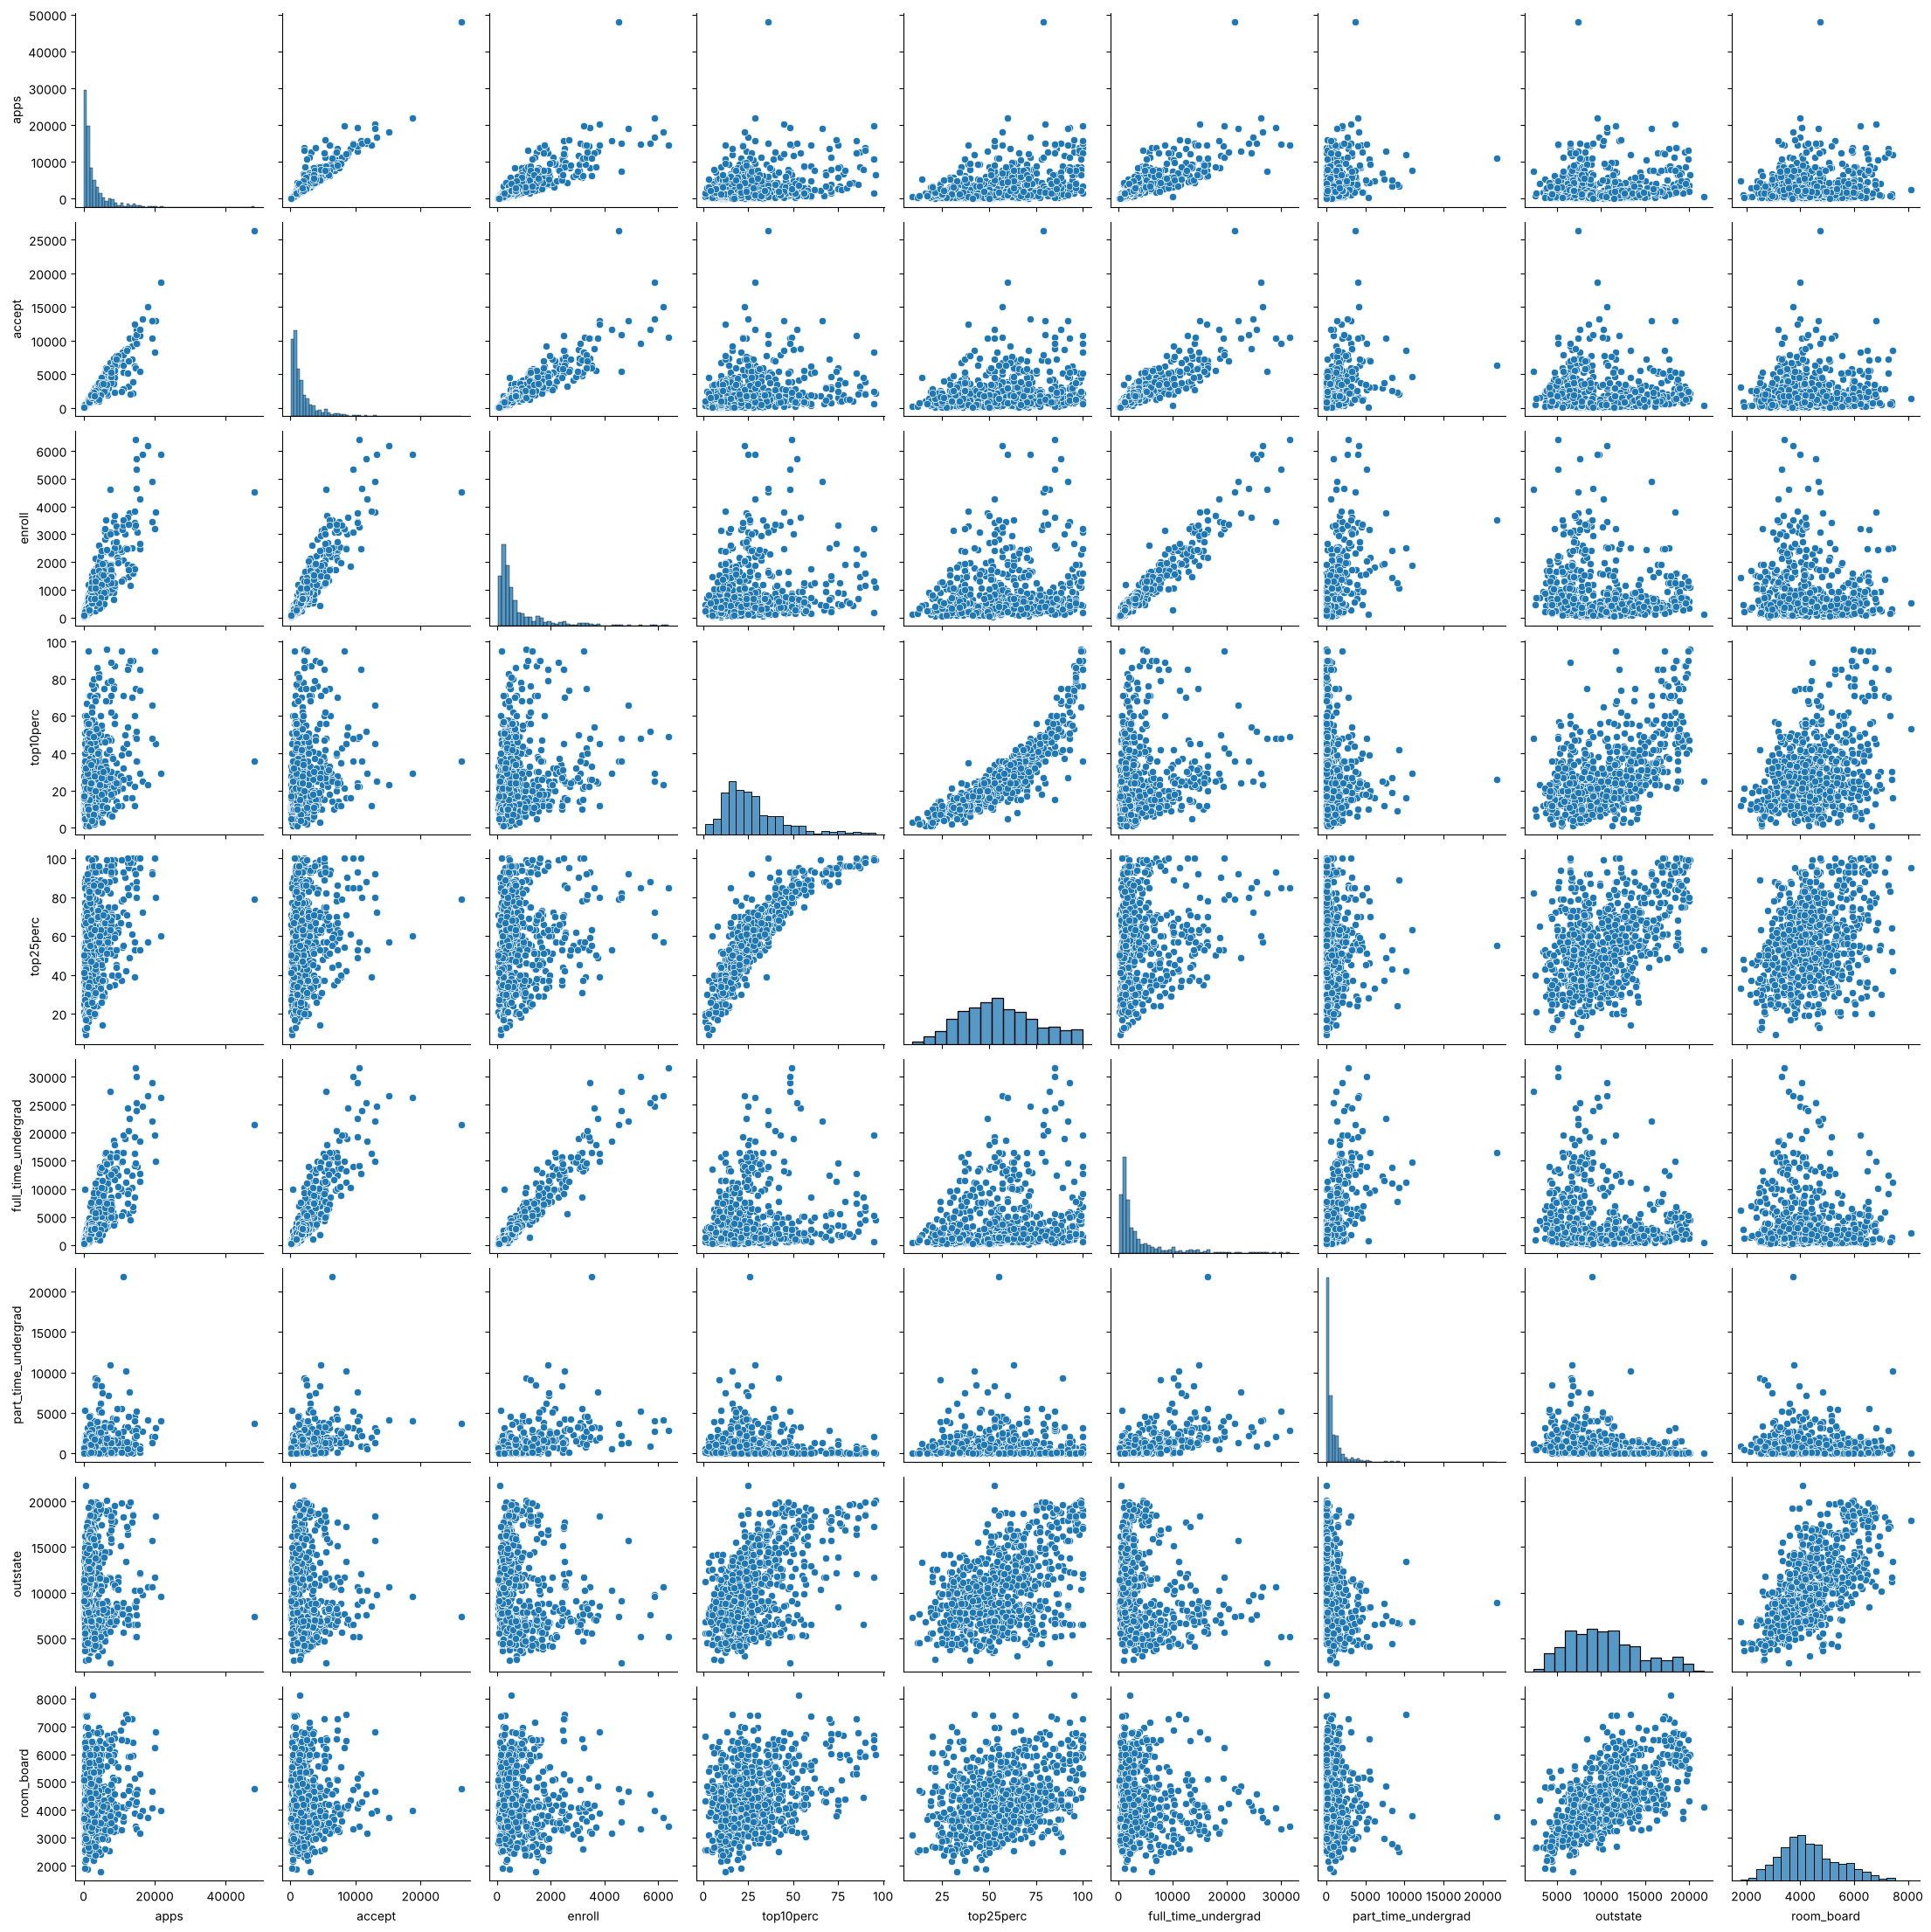

In [7]:
eda_columns = [
    "apps", "accept", "enroll", "top10perc", "top25perc",
    "full_time_undergrad", "part_time_undergrad", "outstate", "room_board"
]

sns.pairplot(college[eda_columns].dropna())
plt.show()


**Interpretation:** Applications, acceptances, and enrollments show strong positive relationships. The two academic-quality measures, `top10perc` and `top25perc`, are also strongly related. Several size-related variables are right-skewed, indicating that a relatively small number of institutions are much larger than the rest.


### 5.2 Private vs. Public Tuition


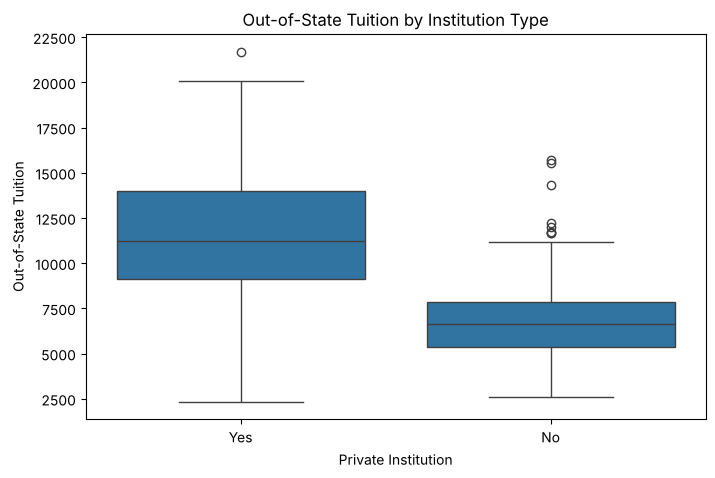

,count,mean,median
private,,,
No,212,6813.410377,6609.0
Yes,565,11801.693805,11200.0


In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=college, x="private", y="outstate")
plt.title("Out-of-State Tuition by Institution Type")
plt.xlabel("Private Institution")
plt.ylabel("Out-of-State Tuition")
plt.show()

college.groupby("private")["outstate"].agg(["count", "mean", "median"])


In [9]:
# Welch's t-test (unequal variances) plus a rank-based check that doesn't assume normality.
private_tuition = college.loc[college["private"] == "Yes", "outstate"]
public_tuition = college.loc[college["private"] == "No", "outstate"]

t_private, p_private = stats.ttest_ind(private_tuition, public_tuition, equal_var=False)
u_private, p_private_u = stats.mannwhitneyu(private_tuition, public_tuition, alternative="two-sided")

print(f"Private mean ${private_tuition.mean():,.0f} (n={len(private_tuition)}), "
      f"public mean ${public_tuition.mean():,.0f} (n={len(public_tuition)})")
print(f"Difference in means: ${private_tuition.mean() - public_tuition.mean():,.0f}")
print(f"Welch t = {t_private:.2f}, p = {p_private:.2e};  Mann-Whitney p = {p_private_u:.2e}")

Private mean $11,802 (n=565), public mean $6,813 (n=212)
Difference in means: $4,988
Welch t = 23.25, p = 2.49e-87;  Mann-Whitney p = 8.31e-63


**Interpretation:** Private institutions charge substantially more. Mean out-of-state tuition is $11,802 at private institutions (n = 565) and $6,813 at public ones (n = 212), a difference of about $4,990 in 1995 dollars. The difference is far beyond chance under both Welch's t-test and the Mann-Whitney test (p < 10⁻⁶⁰), so the conclusion doesn't depend on assuming normal tuition distributions.

## 6. Feature Engineering: University Size


In [10]:
average_enrollment = college["enroll"].mean()

college["large_university"] = np.where(
    college["enroll"] > average_enrollment,
    "Large",
    "Small"
)

print(f"Average enrollment threshold: {average_enrollment:,.1f}")
college["large_university"].value_counts()


Average enrollment threshold: 780.0


large_university
Small    559
Large    218
Name: count, dtype: int64

In [11]:
large_universities = college[college["large_university"] == "Large"]
large_universities.describe(include="all")


,private,apps,accept,enroll,top10perc,top25perc,full_time_undergrad,part_time_undergrad,outstate,room_board,books,personal,phd,terminal,student_faculty_ratio,alumni_donation_rate,expend,grad_rate,names,large_university
count,218,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218.000000,218,218
unique,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,218,1
top,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Angelo State University,Large
freq,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,218
mean,NaN,7233.376147,4734.110092,1897.229358,31.224771,60.298165,9455.123853,1995.334862,9258.600917,4311.839450,581.032110,1661.110092,80.853211,86.481651,15.493578,18.119266,10663.669725,63.963303,NaN,NaN
std,NaN,5069.744625,3186.820612,1124.121061,21.994342,21.117579,5978.291505,2369.873736,4409.338645,1246.859667,173.273615,736.371392,11.160600,10.222508,4.764428,10.702276,7803.519970,18.260494,NaN,NaN
min,NaN,1256.000000,1068.000000,781.000000,3.000000,18.000000,1320.000000,16.000000,2340.000000,1780.000000,96.000000,300.000000,37.000000,43.000000,3.300000,0.000000,3605.000000,10.000000,NaN,NaN
25%,NaN,3943.250000,2686.500000,1058.000000,15.000000,45.000000,5023.250000,658.500000,6197.250000,3413.000000,500.000000,1153.000000,74.000000,81.000000,13.125000,10.000000,6313.500000,52.000000,NaN,NaN
50%,NaN,6003.500000,3752.500000,1548.000000,25.000000,57.500000,7533.500000,1354.500000,7822.000000,4077.500000,599.000000,1583.500000,82.000000,89.000000,16.300000,16.000000,8100.500000,63.500000,NaN,NaN
75%,NaN,8756.500000,5692.250000,2408.000000,40.000000,74.500000,12791.750000,2574.000000,11596.000000,5085.500000,650.000000,2000.000000,89.000000,94.000000,18.975000,23.000000,11016.500000,75.000000,NaN,NaN


### 6.1 Does University Size Affect Tuition?


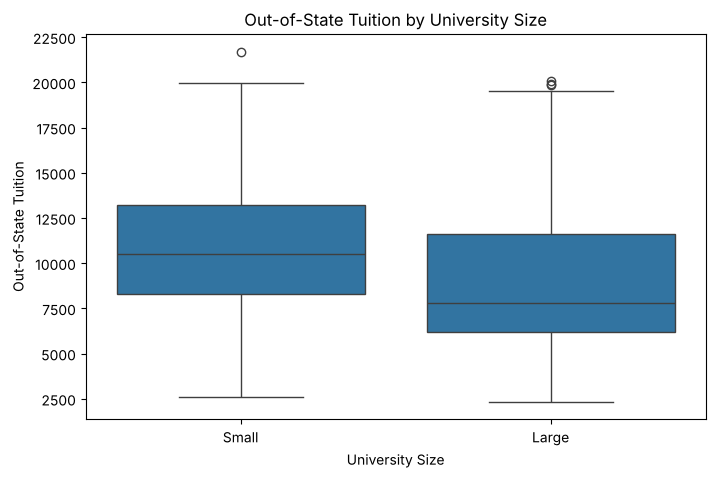

,count,mean,median
large_university,,,
Large,218,9258.600917,7822.0
Small,559,10901.654741,10520.0


In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=college, x="large_university", y="outstate")
plt.title("Out-of-State Tuition by University Size")
plt.xlabel("University Size")
plt.ylabel("Out-of-State Tuition")
plt.show()

college.groupby("large_university")["outstate"].agg(["count", "mean", "median"])


In [13]:
large_tuition = college.loc[college["large_university"] == "Large", "outstate"]
small_tuition = college.loc[college["large_university"] == "Small", "outstate"]

t_size, p_size = stats.ttest_ind(large_tuition, small_tuition, equal_var=False)
_, p_size_u = stats.mannwhitneyu(large_tuition, small_tuition, alternative="two-sided")

print(f"Large median ${large_tuition.median():,.0f} (n={len(large_tuition)}), "
      f"small median ${small_tuition.median():,.0f} (n={len(small_tuition)})")
print(f"Welch t = {t_size:.2f}, p = {p_size:.2e};  Mann-Whitney p = {p_size_u:.2e}")

# Size and tuition are confounded with institution type: most large schools are public.
pd.crosstab(college["large_university"], college["private"], margins=True)

Large median $7,822 (n=218), small median $10,520 (n=559)
Welch t = -4.85, p = 1.83e-06;  Mann-Whitney p = 1.33e-10


private,No,Yes,All
large_university,,,
Large,151,67,218
Small,61,498,559
All,212,565,777


**Interpretation:** Larger universities are not more expensive. The reverse holds: "large" institutions (enrollment above the mean of 780) have a median out-of-state tuition of $7,822, against $10,520 for smaller ones (Mann-Whitney p ≈ 10⁻¹⁰).

This is largely a **public/private effect, not a size effect**. 151 of the 218 large institutions are public, while 498 of the 559 small ones are private, and public schools charge less (above). Comparing sizes within each institution type would be needed to isolate size.

### 6.2 Enrollment and Tuition Relationship


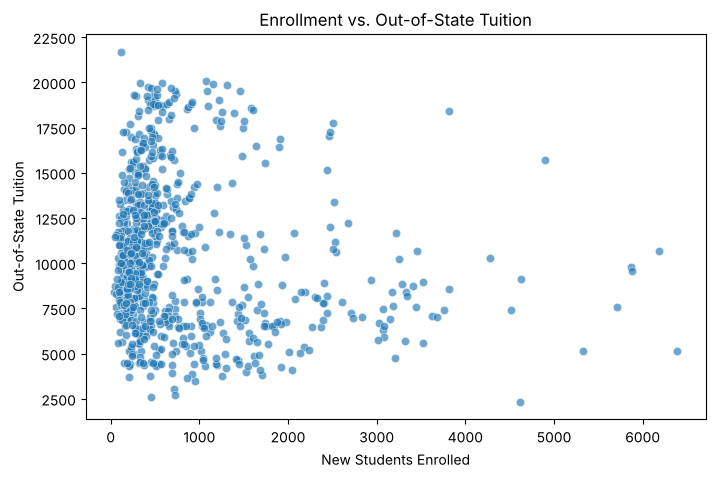

Pearson correlation: -0.155


In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=college, x="enroll", y="outstate", alpha=0.65)
plt.title("Enrollment vs. Out-of-State Tuition")
plt.xlabel("New Students Enrolled")
plt.ylabel("Out-of-State Tuition")
plt.show()

enroll_tuition_corr = college[["enroll", "outstate"]].corr().iloc[0, 1]
print(f"Pearson correlation: {enroll_tuition_corr:.3f}")


**Interpretation:** Enrollment and out-of-state tuition have only a weak negative linear relationship (Pearson r = −0.155), so enrollment alone is a poor predictor of tuition. This is consistent with the group comparison above.

## 7. Distribution of Applications


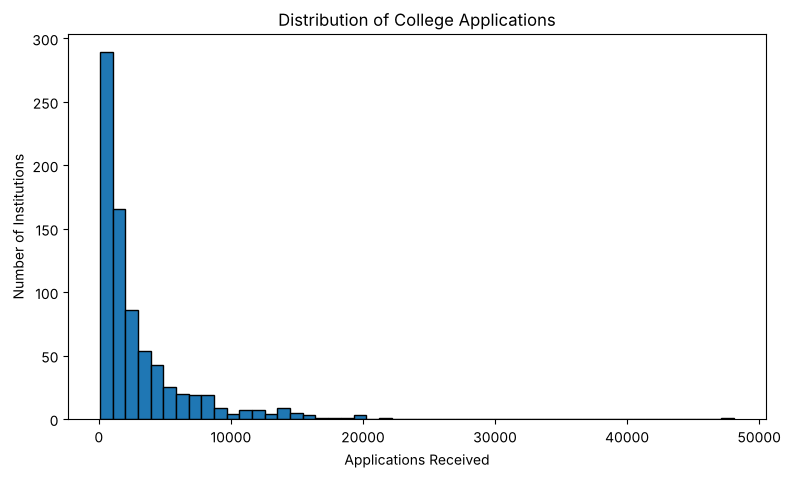

Institutions receiving 0–9,999 applications: 732
Institutions receiving 10,000–19,999 applications: 42


In [15]:
plt.figure(figsize=(9, 5))
plt.hist(college["apps"], bins=50, edgecolor="black")
plt.title("Distribution of College Applications")
plt.xlabel("Applications Received")
plt.ylabel("Number of Institutions")
plt.show()

under_10k = college["apps"].between(0, 10_000, inclusive="left").sum()
between_10k_20k = college["apps"].between(10_000, 20_000, inclusive="left").sum()

print(f"Institutions receiving 0–9,999 applications: {under_10k}")
print(f"Institutions receiving 10,000–19,999 applications: {between_10k_20k}")


**Interpretation:** 732 of the 777 institutions receive fewer than 10,000 applications, and only 42 receive 10,000–19,999. The distribution is strongly right-skewed: a handful of universities receive very large application volumes.

## 8. Acceptance Rate and Student Academic Profile


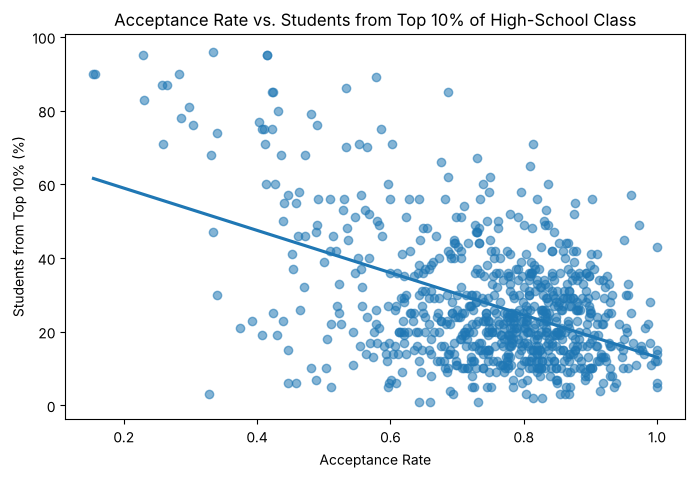

Pearson correlation: -0.479


In [16]:
college_analysis = college.copy()

college_analysis["acceptance_rate"] = np.where(
    college_analysis["apps"] > 0,
    college_analysis["accept"] / college_analysis["apps"],
    np.nan
)

plt.figure(figsize=(8, 5))
sns.regplot(
    data=college_analysis,
    x="acceptance_rate",
    y="top10perc",
    scatter_kws={"alpha": 0.55},
    ci=None,
)
plt.title("Acceptance Rate vs. Students from Top 10% of High-School Class")
plt.xlabel("Acceptance Rate")
plt.ylabel("Students from Top 10% (%)")
plt.show()

acceptance_top10_corr = (
    college_analysis[["acceptance_rate", "top10perc"]]
    .dropna()
    .corr()
    .iloc[0, 1]
)
print(f"Pearson correlation: {acceptance_top10_corr:.3f}")


**Interpretation:** Acceptance rate has a moderate negative relationship with the share of students from the top 10% of their high-school class (Pearson r = −0.479). More selective institutions tend to enroll academically stronger incoming classes.

## 9. Hypothesis Test 1: PhD Faculty and Selectivity


### Hypotheses

- **H₀:** There is no statistically significant relationship between the percentage of faculty with PhDs and acceptance rate.
- **H₁:** A higher percentage of PhD-qualified faculty is associated with a lower acceptance rate.


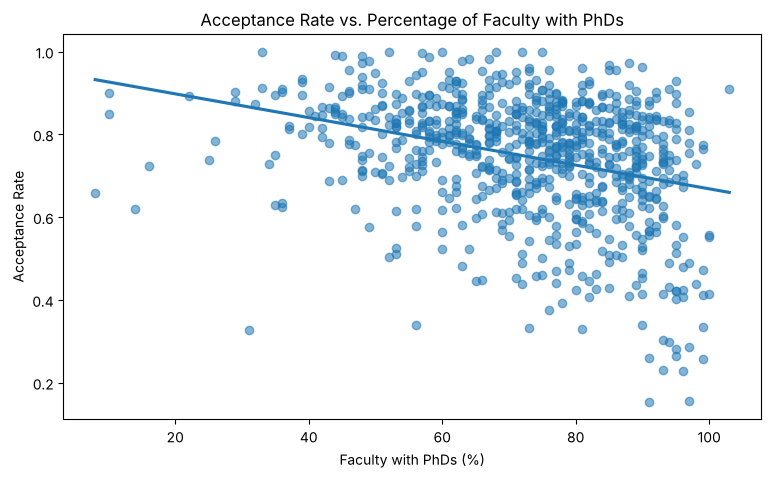

n = 777
Pearson r = -0.3183, two-sided p = 9.2965e-20  (r^2 = 0.101)
Spearman rho = -0.3192, p = 7.2257e-20  (rank-based robustness check)


In [17]:
rq1_data = college_analysis[["phd", "acceptance_rate"]].dropna()

r1, p1 = stats.pearsonr(
    rq1_data["phd"],
    rq1_data["acceptance_rate"]
)

plt.figure(figsize=(9, 5))
sns.regplot(
    data=rq1_data,
    x="phd",
    y="acceptance_rate",
    scatter_kws={"alpha": 0.55},
    ci=None,
)
plt.title("Acceptance Rate vs. Percentage of Faculty with PhDs")
plt.xlabel("Faculty with PhDs (%)")
plt.ylabel("Acceptance Rate")
plt.show()

rho1, p1_s = stats.spearmanr(rq1_data["phd"], rq1_data["acceptance_rate"])

print(f"n = {len(rq1_data)}")
print(f"Pearson r = {r1:.4f}, two-sided p = {p1:.4e}  (r^2 = {r1**2:.3f})")
print(f"Spearman rho = {rho1:.4f}, p = {p1_s:.4e}  (rank-based robustness check)")


### Interpretation

Across all 777 institutions, the share of faculty with PhDs is **negatively** correlated with acceptance rate: Pearson r = −0.318 and Spearman ρ = −0.319, both with p < 10⁻¹⁸. We reject H₀. The sign matches H₁, which is directional, even though the test is two-sided.

The relationship is **statistically significant but weak**. PhD share explains about 10% of the variation in acceptance rates (r² = 0.10), so many institutions with highly credentialed faculty still admit most applicants. With n = 777, even small correlations reach significance, so effect size matters more than the p-value here.

This is an association, not proof that faculty credentials cause selectivity. Wealthier, research-oriented institutions tend to have both.

## 10. Hypothesis Test 2: Tuition and Application Volume


### Hypotheses

- **H₀:** Out-of-state tuition is not related to the number of applications.
- **H₁:** Higher out-of-state tuition is associated with fewer applications.


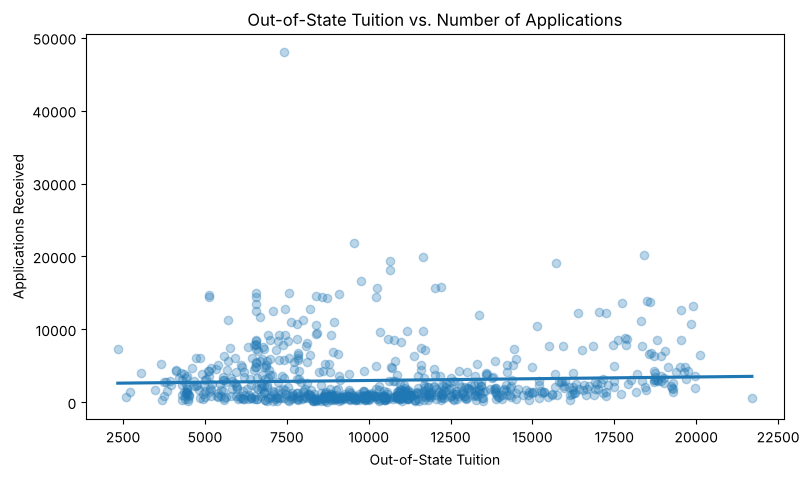

n = 777
Pearson r = 0.0502, two-sided p = 0.1625
Spearman rho = 0.0494, p = 1.6896e-01  (applications are heavily right-skewed)


In [18]:
rq2_data = college_analysis[["outstate", "apps"]].dropna()

r2, p2 = stats.pearsonr(
    rq2_data["outstate"],
    rq2_data["apps"]
)

plt.figure(figsize=(9, 5))
sns.regplot(
    data=rq2_data,
    x="outstate",
    y="apps",
    scatter_kws={"alpha": 0.30},
    ci=None,
)
plt.title("Out-of-State Tuition vs. Number of Applications")
plt.xlabel("Out-of-State Tuition")
plt.ylabel("Applications Received")
plt.show()

rho2, p2_s = stats.spearmanr(rq2_data["outstate"], rq2_data["apps"])

print(f"n = {len(rq2_data)}")
print(f"Pearson r = {r2:.4f}, two-sided p = {p2:.4f}")
print(f"Spearman rho = {rho2:.4f}, p = {p2_s:.4e}  (applications are heavily right-skewed)")


### Interpretation

Out-of-state tuition and applications are essentially uncorrelated: Pearson r = 0.050 (p = 0.16) and Spearman ρ = 0.049 (p = 0.17). We **fail to reject H₀**. There's no evidence that higher tuition is associated with fewer applications, and the small positive sign is the opposite of H₁.

Application volume is driven mostly by other factors, such as size, reputation, location, program offerings and financial aid. Public universities are both cheaper and larger, which pushes the raw association in opposite directions.

## 11. Key Findings


All figures describe US colleges in **1995**.

- **Private institutions charge more:** a mean out-of-state tuition of $11,802 vs $6,813 at public ones (p < 10⁻⁶⁰).
- **Larger institutions charge less, not more:** a median of $7,822 vs $10,520. This mostly reflects that large institutions are usually public. Within the full sample, enrollment and tuition are only weakly correlated (r = −0.155).
- **Applications are highly concentrated:** 732 of 777 institutions receive fewer than 10,000.
- **Selectivity tracks student quality:** acceptance rate vs the share of top-10% students, r = −0.479 (moderate).
- **Selectivity tracks faculty credentials, weakly:** acceptance rate vs the share of PhD faculty, r = −0.318 (p < 10⁻¹⁸, r² = 0.10).
- **Tuition doesn't explain application volume:** r = 0.050, p = 0.16.

## 12. Limitations and Future Improvements


### Limitations

- The analysis is observational and does not establish causation.
- Pearson correlation captures only linear relationships.
- The data is a single 1995 cross-section; tuition levels and relationships may differ today.
- Potential confounders are not controlled. Institution type (public/private) confounds the size-tuition comparison, and institutional wealth plausibly drives both faculty credentials and selectivity.

### Future Improvements

- Build multivariate regression models for acceptance rate and application volume.
- Examine public and private institutions separately.
- Use robust statistical methods for skewed variables and outliers.
- Add interactive Plotly visualizations.
- Create a dashboard summarizing tuition, enrollment, and selectivity.


## Conclusion

This project takes one dataset from loading and validation through feature engineering, visualization and hypothesis testing.

- **Selectivity:** acceptance rate is more closely associated with academic characteristics, both incoming-student profile (r = −0.48) and, more weakly, faculty credentials (r = −0.32), than with institution size.
- **Tuition:** separately, tuition is explained mainly by whether an institution is public or private, and it shows no relationship with how many applications an institution receives.